In [6]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [4]:
#
np.random.seed(42)

In [7]:
#Simulate temperate from 0 to 40 C
temperatures = np.linspace(0,40, 500)
temperatures

array([ 0.        ,  0.08016032,  0.16032064,  0.24048096,  0.32064128,
        0.4008016 ,  0.48096192,  0.56112224,  0.64128257,  0.72144289,
        0.80160321,  0.88176353,  0.96192385,  1.04208417,  1.12224449,
        1.20240481,  1.28256513,  1.36272545,  1.44288577,  1.52304609,
        1.60320641,  1.68336673,  1.76352705,  1.84368737,  1.9238477 ,
        2.00400802,  2.08416834,  2.16432866,  2.24448898,  2.3246493 ,
        2.40480962,  2.48496994,  2.56513026,  2.64529058,  2.7254509 ,
        2.80561122,  2.88577154,  2.96593186,  3.04609218,  3.12625251,
        3.20641283,  3.28657315,  3.36673347,  3.44689379,  3.52705411,
        3.60721443,  3.68737475,  3.76753507,  3.84769539,  3.92785571,
        4.00801603,  4.08817635,  4.16833667,  4.24849699,  4.32865731,
        4.40881764,  4.48897796,  4.56913828,  4.6492986 ,  4.72945892,
        4.80961924,  4.88977956,  4.96993988,  5.0501002 ,  5.13026052,
        5.21042084,  5.29058116,  5.37074148,  5.4509018 ,  5.53

In [8]:
# Simu;ate plant growth based on temperature (growth increases to a peak, ten declines)
growth = -0.1 * (temperatures - 25) ** 2 + 50 + np.random.normal(0, 5, size=temperatures.shape)
growth

array([-10.01642923, -12.79116247,  -8.46252437,  -3.68822902,
       -12.07784154, -11.68274096,  -2.22225874,  -5.88870095,
       -11.68208344,  -6.23203334, -10.8733292 , -10.49758182,
        -6.57309915, -16.96457432, -15.63930999,  -9.44399133,
       -11.31582728,  -4.30083815, -10.03388345, -12.17825499,
         2.58724883,  -5.49542019,  -3.65572647, -10.74522237,
        -5.97279414,  -2.32695178,  -8.26850197,  -0.26829848,
        -4.78452164,  -2.87562169,  -4.0627959 ,   8.56873306,
        -0.39982415,  -5.26185796,   4.49717081,  -5.36330757,
         2.14040795,  -8.34836648,  -4.83833708,   3.13822323,
         6.19628871,   3.70955083,   2.6219365 ,   2.04084278,
        -3.50135048,   0.63565151,   2.27400664,  10.20385443,
         6.97609242,  -3.21872727,   7.55408076,   4.34415177,
         3.2195703 ,   9.99589374,  12.42455677,  12.25672148,
         3.73370985,   6.71192704,  10.2412124 ,  13.78824206,
         6.83898128,   8.6296085 ,   4.34799429,   4.21

In [12]:
# Step 2: Reshape temeprature data for linear regression ( requires 2D input for X)
temperatures = temperatures.reshape(-1, 1)
temperatures

X = temperatures.reshape(-1, 1)
Y = growth

In [13]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("mn", MLPRegressor(
        hidden_layer_sizes=(50,50),
        activation="relu",
        solver="adam",
        max_iter=5000,
        random_state=42
    ))
])
model.fit(X, Y)

Pipeline(steps=[('scaler', StandardScaler()),
                ('mn',
                 MLPRegressor(hidden_layer_sizes=(50, 50), max_iter=5000,
                              random_state=42))])

In [19]:
# Step 4: Predict growth using the trained model
Y_pred = model.predict(temperatures)
Y_pred

array([-1.13225800e+01, -1.09988741e+01, -1.06751681e+01, -1.03514621e+01,
       -1.00277561e+01, -9.70405012e+00, -9.38034414e+00, -9.05663815e+00,
       -8.73293217e+00, -8.40922618e+00, -8.08552020e+00, -7.76181421e+00,
       -7.43810823e+00, -7.11440224e+00, -6.79069626e+00, -6.46699027e+00,
       -6.14328429e+00, -5.81957830e+00, -5.49587232e+00, -5.17216633e+00,
       -4.84846035e+00, -4.52475436e+00, -4.20104838e+00, -3.87734240e+00,
       -3.55363641e+00, -3.22993043e+00, -2.90622444e+00, -2.58251846e+00,
       -2.25881247e+00, -1.93510649e+00, -1.61140050e+00, -1.28769452e+00,
       -9.63988532e-01, -6.40282547e-01, -3.16576562e-01,  7.12942265e-03,
        3.30835407e-01,  6.54541392e-01,  9.78247377e-01,  1.30195336e+00,
        1.62565935e+00,  1.94936533e+00,  2.27307132e+00,  2.59677730e+00,
        2.92048329e+00,  3.24418927e+00,  3.56789526e+00,  3.89160124e+00,
        4.21530723e+00,  4.53901321e+00,  4.86271920e+00,  5.18642518e+00,
        5.51013116e+00,  

In [16]:
# Step 5: Evalaute the model
mae = mean_absolute_error(growth, growth_pred) # Mean Absolute Error
mse = mean_squared_error(growth, growth_pred) # Mean Squared Error
rmse = np.sqrt(mse) # Root Mean Squared Error
r2= r2_score(growth, growth_pred) # R^2 Score|

In [24]:
# Print the evaluation metrics
print(f'Mean Absolute Error (MAE): {mae: .2f}')
print(f'Mean Squared Error (MSE): {mse: .2f}')
print(f'Root Mean Squared Error (RMSE): {rmse: .2f}')
print(f'R^2 Score: {r2: .2f}')

Mean Absolute Error (MAE):  3.88
Mean Squared Error (MSE):  23.82
Root Mean Squared Error (RMSE):  4.88
R^2 Score:  0.92


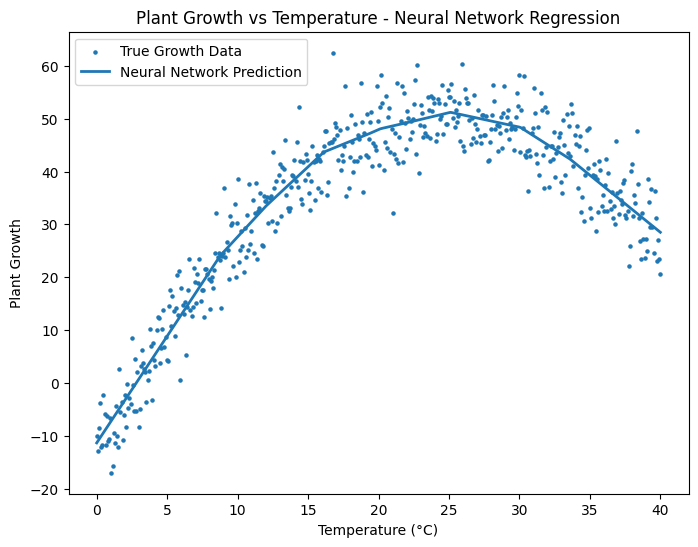

In [20]:
# Visualize Results
plt.figure(figsize=(8,6))
plt.scatter(X ,Y, label = 'True Growth Data', s=5)
plt.plot(X ,Y_pred, linewidth= 2, label = 'Neural Network Prediction')
plt.title('Plant Growth vs Temperature - Neural Network Regression')
plt.xlabel('Temperature (°C)')
plt.ylabel('Plant Growth')
plt.legend()
plt.show()